# L12 — Neural Networks, Convolution and Pooling: Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-F26/blob/main/Notebooks/L12-NeuralNets/L12_Neural_Networks.ipynb)

This notebook accompanies **Lecture 12**, the first lecture of Unit 3 (deep learning).
Every filter we have used so far — Sobel, Gaussian, Harris, SIFT — was **designed by a
person**. Today the computer **learns** the numbers from examples.

We use two kinds of data:
- one of the **1958 frames** from AL5 (to learn a filter whose answer we know: Sobel), and
- the **8 × 8 handwritten digits** that come with scikit-learn (no download), to train a
  small network and a small convolutional network (CNN).

Everything runs on a CPU in well under a minute. On Colab, a GPU is not needed.

| Section | Topic |
|---------|-------|
| 0 | Setup and data |
| 1 | Warm-up: learn a 3 × 3 kernel from examples |
| 2 | One neuron = a filter response + a switch |
| 3 | One neuron draws one line: AND, OR — and XOR needs a hidden layer |
| 4 | Why the ReLU matters |
| 5 | Gradient descent on one weight |
| 6 | Backpropagation by hand, then by PyTorch |
| 7 | A small network for digits |
| 8 | From fully connected to convolution |
| 9 | Output size and pooling |
| 10 | A small CNN for digits, compared with the network from §7 |
| 11 | What did the CNN learn? |
| 12 | Try at home |

In [1]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                              "#1A3A5C", "#7B4EA0", "#7A8FA6")
torch.set_num_threads(2)
print("PyTorch", torch.__version__, "| OpenCV", cv2.__version__)

PyTorch 2.11.0+cpu | OpenCV 4.14.0


## 0 · Setup and data

**AL5** (twenty raw 1958 frames, the same zip as AL5, L8–L11). Safe to re-run.

In [2]:
import io, os, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

fetch_zip("AL5.zip", ["frames/16046-19.jpg"])
frame = cv2.imread("frames/16046-19.jpg", cv2.IMREAD_GRAYSCALE)
crop = frame[300:556, 300:556].astype(np.float32) / 255      # 256 x 256, values 0..1
print("frame", frame.shape, "| crop", crop.shape)

AL5.zip: 7.6 MB downloaded and extracted
frame (1000, 953) | crop (256, 256)


In [3]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()                                  # 1,797 images, 8 x 8, values 0..16
X = digits.images.astype(np.float32) / 16
y = digits.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print(f"train {len(Xtr)}  test {len(Xte)}  image {X.shape[1:]}")

train 1257  test 540  image (8, 8)


## 1 · Warm-up: learn a 3 × 3 kernel from examples

In L3 (and on Test 1) you matched kernels to outputs. Now turn it around: we give the computer
the **input** and the **output** of a filter, and it has to find the **9 numbers**.

The hidden filter is Sobel-x from L3. The computer starts from 9 random numbers, measures
how wrong its output is (the **loss**: mean squared difference), and nudges every number
downhill, 500 times. Sections 5–6 explain the nudging.

In [4]:
#Unknown to the NN this is the filter that produces the output
SOBEL_X = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], np.float32)


target = cv2.filter2D(crop, -1, SOBEL_X, borderType=cv2.BORDER_CONSTANT)   # the 'unknown' filter's output

x_t = torch.tensor(crop)[None, None]        # shape (1, 1, 256, 256): batch, channel (grayscale), rows, cols

t_t = torch.tensor(target)[None, None]

torch.manual_seed(0)
layer = nn.Conv2d(1, 1, kernel_size=3, padding=1, bias=False)   # one 3x3 filter, 9 weights (all starting from random init)
opt = torch.optim.SGD(layer.parameters(), lr=0.5)

snap, losses = {}, []
for step in range(501):
    if step in (0, 50, 500):
        snap[step] = (layer.weight.detach().numpy()[0, 0].copy(), layer(x_t).detach().numpy()[0, 0])
    out = layer(x_t)
    loss = ((out - t_t) ** 2).mean() # Mean squared diff between output and target
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())

print("loss at step 0, 50, 500:", [f"{losses[i]:.2g}" for i in (0, 50, 500)])
print("learned kernel:\n", snap[500][0].round(2))

loss at step 0, 50, 500: ['0.28', '0.024', '6.2e-06']
learned kernel:
 [[-1.01  0.01  1.  ]
 [-1.98 -0.01  2.  ]
 [-1.01  0.01  1.  ]]


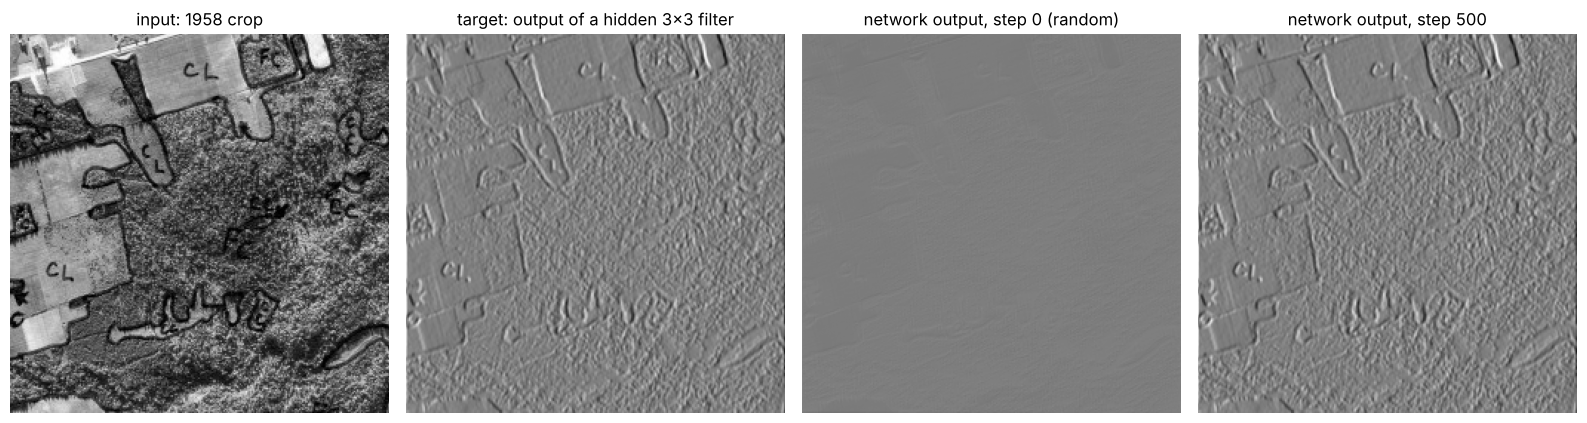

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
v = np.abs(target).max()
for a, (im, title) in zip(ax, [(crop, "input: 1958 crop"),
                               (target, "target: output of a hidden 3×3 filter"),
                               (snap[0][1], "network output, step 0 (random)"),
                               (snap[500][1], "network output, step 500")]):
    a.imshow(im, cmap="gray", vmin=0 if im is crop else -v, vmax=1 if im is crop else v)
    a.set_title(title, fontsize=12); a.axis("off")
plt.tight_layout(); plt.show()

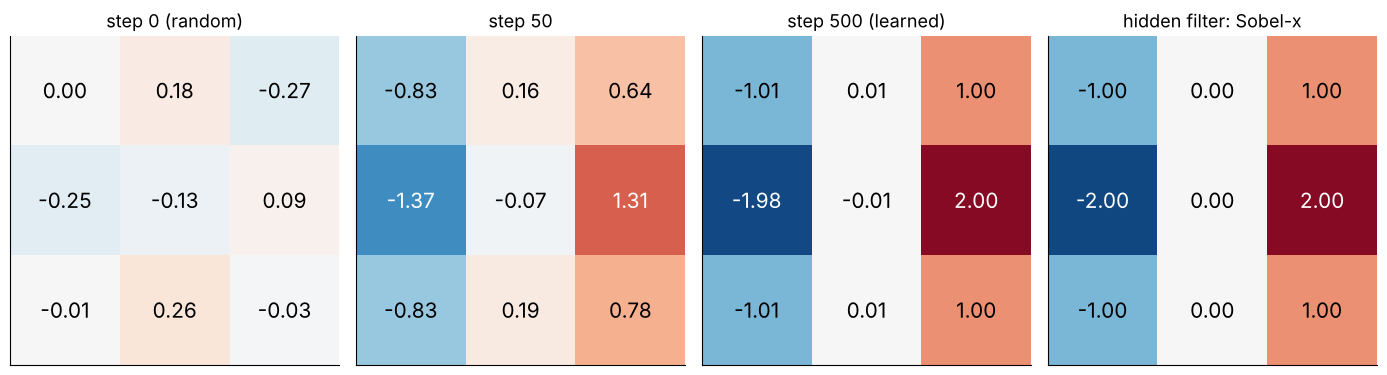

In [ ]:
def show_kernel(a, k, title, vmax=2.2):
    a.imshow(k, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    for r in range(3):
        for c in range(3):
            val = k[r, c] if abs(k[r, c]) >= 0.005 else 0.0
            a.text(c, r, f"{val:.2f}", ha="center", va="center", fontsize=15,
                   color="white" if abs(k[r, c]) > 1.3 else "black")
    a.set_title(title, fontsize=13); a.set_xticks([]); a.set_yticks([])

fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
show_kernel(ax[0], snap[0][0], "step 0 (random)")
show_kernel(ax[1], snap[50][0], "step 50")
show_kernel(ax[2], snap[500][0], "step 500 (learned)")
show_kernel(ax[3], SOBEL_X, "hidden filter: Sobel-x")
plt.tight_layout(); plt.show()

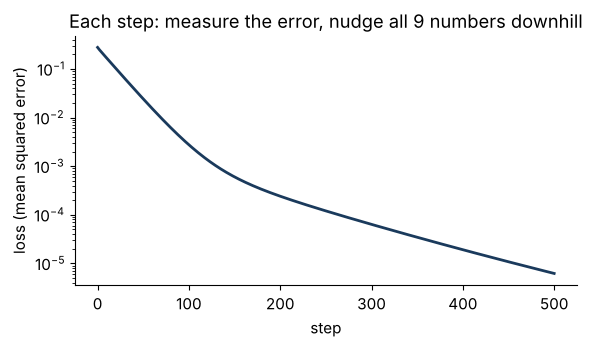

In [ ]:
plt.figure(figsize=(6, 3.6))
plt.semilogy(losses, color=NAVY, lw=2)
plt.xlabel("step"); plt.ylabel("loss (mean squared error)")
plt.title("Each step: measure the error, nudge all 9 numbers downhill")
plt.tight_layout(); plt.show()

The network found Sobel to two decimals. Nobody told it about edges or derivatives: it only
saw an input, the output we wanted, and a rule for reducing the error. A **convolutional
network** is this, with many filters, stacked in layers, learned from labelled examples.

## 2 · One neuron = a filter response + a switch

A neuron computes a **weighted sum** of its inputs plus a **bias**, then passes it through an
**activation**. The most common activation is the **ReLU**: keep positive values, replace
negative values with 0.

$$z = w_1 x_1 + \dots + w_n x_n + b, \qquad a = \mathrm{ReLU}(z) = \max(0, z)$$

The weighted sum is exactly one pixel of an L3 filter: Σ (pixel × weight). Below, the 9
inputs are a 3 × 3 patch, the weights are Sobel-x, and the bias −100 means "only fire for a
strong edge" — like Canny's high threshold.

In [ ]:
def neuron(patch, w, b):
    z = float((patch * w).sum() + b)
    return z, max(0.0, z)

patches = {
    "field edge (10 | 50)": np.array([[10, 10, 50]] * 3, np.float32),
    "flat field (10)":      np.full((3, 3), 10, np.float32),
    "faint edge (10 | 30)": np.array([[10, 10, 30]] * 3, np.float32),
}
for name, p in patches.items():
    z, a = neuron(p, SOBEL_X, b=-100)
    print(f"{name:22s} z = {z:6.0f}   ReLU(z) = {a:4.0f}")

field edge (10 | 50)   z =     60   ReLU(z) =   60
flat field (10)        z =   -100   ReLU(z) =    0
faint edge (10 | 30)   z =    -20   ReLU(z) =    0


## 3 · One neuron draws one line — XOR needs a hidden layer

Take the smallest possible image: **two pixels**, each 0 (dark) or 1 (bright). A neuron
with weights (1, 1) and bias *b* fires when x₁ + x₂ + b > 0, i.e. on one side of a straight
line.

- *b* = −1.5 → fires only when **both** pixels are bright (AND)
- *b* = −0.5 → fires when **at least one** is bright (OR)

**XOR** ("exactly one pixel bright") cannot be done with one line. Two hidden ReLU neurons fix it:

$$h_1 = \mathrm{ReLU}(x_1 + x_2), \quad h_2 = \mathrm{ReLU}(x_1 + x_2 - 1), \quad \text{out} = h_1 - 2 h_2$$

In [ ]:
pts = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], np.float32)
relu = lambda z: np.maximum(0, z)
print(" x1 x2 | AND OR | h1 h2 | XOR = h1 - 2 h2")
for x1, x2 in pts:
    AND = int(x1 + x2 - 1.5 > 0); OR = int(x1 + x2 - 0.5 > 0)
    h1, h2 = relu(x1 + x2), relu(x1 + x2 - 1)
    print(f" {x1:.0f}  {x2:.0f}  |  {AND}   {OR} |  {h1:.0f}  {h2:.0f} |  {h1 - 2*h2:.0f}")

 x1 x2 | AND OR | h1 h2 | XOR = h1 - 2 h2
 0  0  |  0   0 |  0  0 |  0
 0  1  |  0   1 |  1  0 |  1
 1  0  |  0   1 |  1  0 |  1
 1  1  |  1   1 |  2  1 |  0


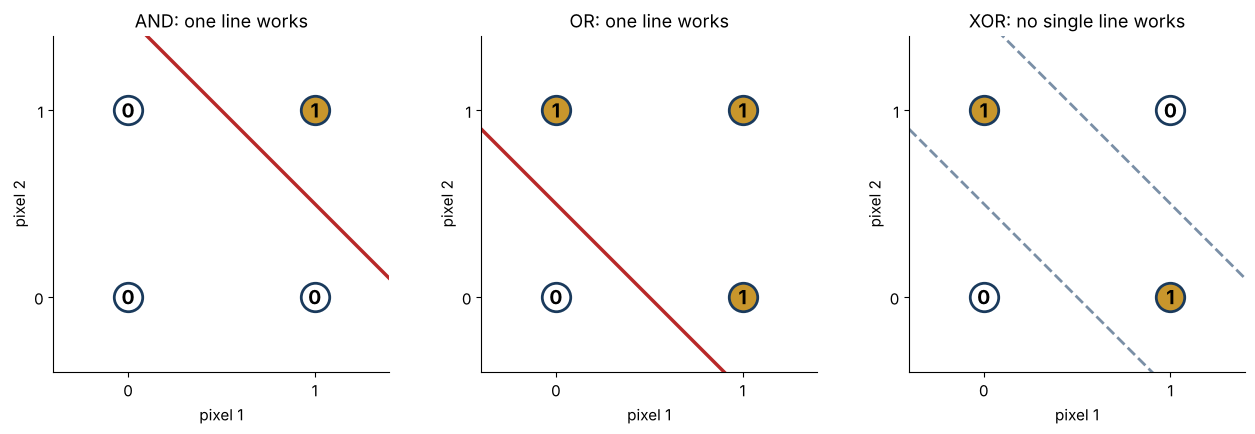

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
labels = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}
xx = np.linspace(-0.4, 1.4, 10)
for a, (name, lab) in zip(ax, labels.items()):
    for (x1, x2), l in zip(pts, lab):
        a.scatter(x1, x2, s=420, color=GOLD if l else "white", edgecolor=NAVY, lw=2, zorder=3)
        a.text(x1, x2, str(l), ha="center", va="center", fontsize=14, fontweight="bold", zorder=4)
    if name == "AND": a.plot(xx, 1.5 - xx, color=RED, lw=2.5); a.set_title("AND: one line works", fontsize=13)
    if name == "OR":  a.plot(xx, 0.5 - xx, color=RED, lw=2.5); a.set_title("OR: one line works", fontsize=13)
    if name == "XOR":
        a.plot(xx, 0.5 - xx, color=GREY, lw=2, ls="--"); a.plot(xx, 1.5 - xx, color=GREY, lw=2, ls="--")
        a.set_title("XOR: no single line works", fontsize=13)
    a.set_xlim(-0.4, 1.4); a.set_ylim(-0.4, 1.4); a.set_aspect("equal")
    a.set_xlabel("pixel 1"); a.set_ylabel("pixel 2"); a.set_xticks([0, 1]); a.set_yticks([0, 1])
plt.tight_layout(); plt.show()

## 4 · Why the ReLU matters

Without an activation, a layer is a matrix multiply. Two layers in a row are one bigger
matrix multiply — **still one layer**. It is the same as L3's associativity: two filters in a
row are one filter. The ReLU (bent at 0) is what lets depth add something.

In [ ]:
rng = np.random.default_rng(1)
W1, W2 = rng.normal(size=(5, 4)), rng.normal(size=(3, 5))
x = rng.normal(size=4)
print("two linear layers :", (W2 @ (W1 @ x)).round(3))
print("one layer W2 @ W1 :", ((W2 @ W1) @ x).round(3))
print("with a ReLU between:", (W2 @ relu(W1 @ x)).round(3), " <- not the same")

# The same thing for filters (L3): blur then Sobel = one combined kernel
G = cv2.getGaussianKernel(5, 1.0); G = (G @ G.T).astype(np.float32)
two = cv2.filter2D(cv2.filter2D(crop, -1, G), -1, SOBEL_X)
K = cv2.filter2D(np.pad(G, 1), -1, SOBEL_X[::-1, ::-1].copy(), borderType=cv2.BORDER_CONSTANT)  # combined 7x7 (one flip: filter2D is correlation)
one = cv2.filter2D(crop, -1, K)
print("blur-then-Sobel vs one combined 7x7 kernel, max diff (interior):",
      f"{np.abs(two - one)[8:-8, 8:-8].max():.1e}")

two linear layers : [-3.568  1.926 -1.659]
one layer W2 @ W1 : [-3.568  1.926 -1.659]
with a ReLU between: [-3.56   0.12   0.366]  <- not the same
blur-then-Sobel vs one combined 7x7 kernel, max diff (interior): 9.5e-07


## 5 · Gradient descent on one weight

One weight *w*, one example: input *x* = 2, wanted output *t* = 6 (so the right answer is
*w* = 3). Loss L(w) = (w·x − t)². Its slope is dL/dw = 2(w·x − t)·x.

**Update:** w ← w − η · slope, where η (eta) is the **learning rate**.

From *w* = 1 with η = 0.05: slope = 2(2 − 6)(2) = −16, so w = 1 + 0.8 = 1.8; then
slope = −9.6, w = 2.28, …

In [ ]:
def descend(eta, w=1.0, steps=8, x=2.0, t=6.0):
    ws = [w]
    for _ in range(steps):
        slope = 2 * (w * x - t) * x
        w = w - eta * slope
        ws.append(w)
    return np.array(ws)

for eta in (0.05, 0.125, 0.3):
    ws = descend(eta)
    print(f"eta = {eta:<5}  w: " + "  ".join(f"{v:6.2f}" for v in ws[:6]))

eta = 0.05   w:   1.00    1.80    2.28    2.57    2.74    2.84
eta = 0.125  w:   1.00    3.00    3.00    3.00    3.00    3.00
eta = 0.3    w:   1.00    5.80   -0.92    8.49   -4.68   13.76


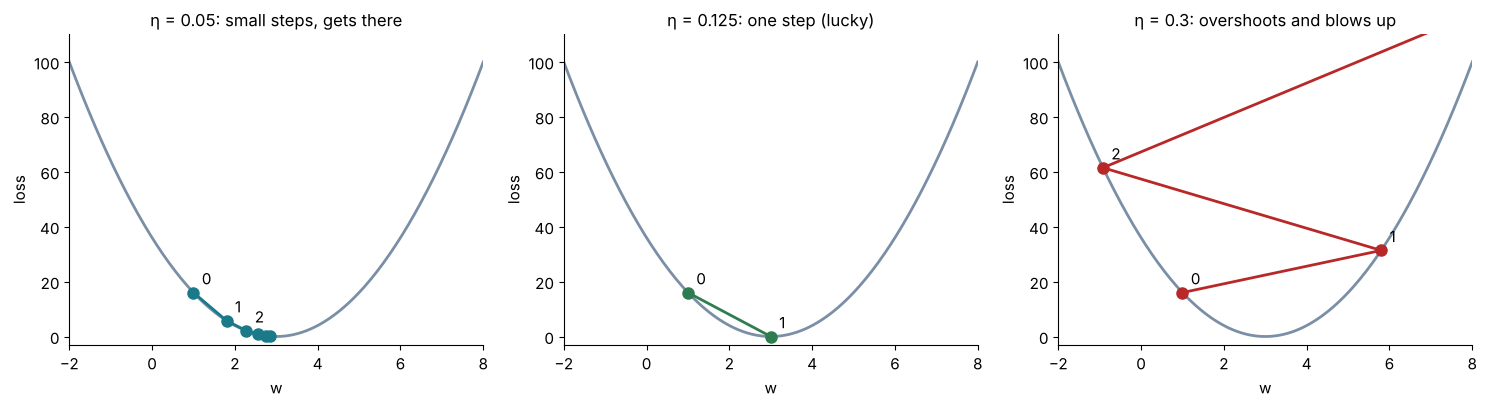

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
wgrid = np.linspace(-2, 8, 200)
for a, eta, col, title in zip(ax, (0.05, 0.125, 0.3), (TEAL, GREEN, RED),
                              ("η = 0.05: small steps, gets there",
                               "η = 0.125: one step (lucky)", "η = 0.3: overshoots and blows up")):
    a.plot(wgrid, (2 * wgrid - 6) ** 2, color=GREY, lw=2)
    ws = descend(eta, steps={0.05: 5, 0.125: 1, 0.3: 3}[eta])
    a.plot(ws, (2 * ws - 6) ** 2, "o-", color=col, ms=8, lw=2)
    for i, w in enumerate(ws[:3] if eta == 0.05 else ws[:4]):
        a.annotate(str(i), (w, (2 * w - 6) ** 2), textcoords="offset points", xytext=(6, 6), fontsize=11)
    a.set_ylim(-3, 110); a.set_xlim(-2, 8); a.set_xlabel("w"); a.set_ylabel("loss")
    a.set_title(title, fontsize=12)
plt.tight_layout(); plt.show()

## 6 · Backpropagation by hand, then by PyTorch

A two-weight network: x → h = ReLU(w₁ x) → y = w₂ h → L = (y − t)².
With x = 1, t = 4, w₁ = 2, w₂ = 3:

**Forward:** h = 2, y = 6, L = 4.

**Backward** (chain rule, from the loss back toward the input; each step multiplies by a local slope):

| quantity | rule | value |
|---|---|---|
| ∂L/∂y | 2(y − t) | 4 |
| ∂L/∂w₂ | ∂L/∂y · h | 8 |
| ∂L/∂h | ∂L/∂y · w₂ | 12 |
| ∂L/∂w₁ | ∂L/∂h · (ReLU slope = 1) · x | 12 |

PyTorch's `loss.backward()` does exactly this, for every weight in the network.

In [ ]:
x, t = torch.tensor(1.0), torch.tensor(4.0)
w1 = torch.tensor(2.0, requires_grad=True)
w2 = torch.tensor(3.0, requires_grad=True)

h = torch.relu(w1 * x); yhat = w2 * h; L = (yhat - t) ** 2
L.backward()
print(f"forward : h = {h.item()}, y = {yhat.item()}, L = {L.item()}")
print(f"backward: dL/dw2 = {w2.grad.item()}, dL/dw1 = {w1.grad.item()}")

with torch.no_grad():                         # one gradient-descent step, eta = 0.01
    w1 -= 0.01 * w1.grad; w2 -= 0.01 * w2.grad
L2 = (w2 * torch.relu(w1 * x) - t) ** 2
print(f"after one step (eta = 0.01): w1 = {w1.item():.2f}, w2 = {w2.item():.2f}, L = {L2.item():.2f}")

forward : h = 2.0, y = 6.0, L = 4.0
backward: dL/dw2 = 8.0, dL/dw1 = 12.0
after one step (eta = 0.01): w1 = 1.88, w2 = 2.92, L = 2.22


## 7 · A small network for digits

64 pixels in → 32 hidden ReLU neurons → 10 output scores (one per digit). The prediction is
the digit with the biggest score. For training, `F.cross_entropy` turns the 10 scores into
probabilities (softmax) and scores −log(probability of the right digit): near 0 when the
network is confident and right, large when it is confident and wrong.

The optimiser is **Adam**, gradient descent with an automatically adjusted step size per
weight (more in L13 and AL7). We show it 32 images at a time (a **mini-batch**); one pass
over the training set is an **epoch**.

/tmp/ipykernel_2744/412748752.py:8: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


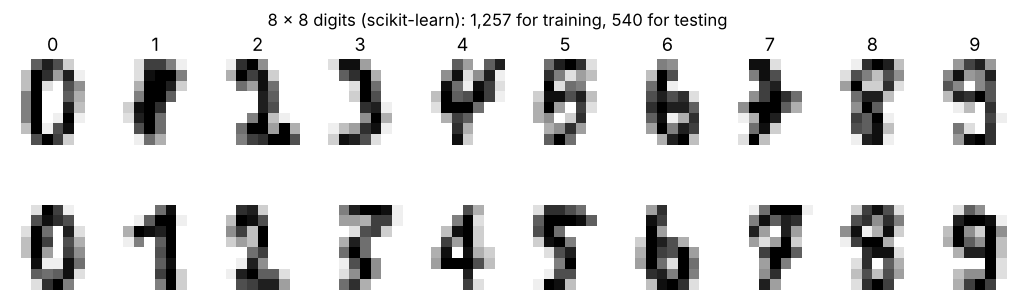

In [ ]:
fig, ax = plt.subplots(2, 10, figsize=(13, 3.4), gridspec_kw={"hspace": 0.25})
for d in range(10):
    for r in range(2):
        i = np.where(ytr == d)[0][r]
        ax[r, d].imshow(Xtr[i], cmap="gray_r"); ax[r, d].axis("off")
    ax[0, d].set_title(str(d), fontsize=13)
plt.suptitle("8 × 8 digits (scikit-learn): 1,257 for training, 540 for testing", fontsize=12)
plt.tight_layout(); plt.show()

In [ ]:
def as_tensor(a):          # (N, 8, 8) numpy -> (N, 1, 8, 8) tensor: batch, channel, rows, cols
    return torch.tensor(a)[:, None]

def accuracy(model, X, y):
    with torch.no_grad():
        return float((model(as_tensor(X)).argmax(1).numpy() == y).mean())

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def train(model, epochs=60, lr=0.01, seed=0):
    torch.manual_seed(seed)
    for m in model.modules():
        if hasattr(m, "reset_parameters"): m.reset_parameters()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    xt, yt = as_tensor(Xtr), torch.tensor(ytr)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(xt))
        for i in range(0, len(xt), 32):
            idx = perm[i:i + 32]
            loss = F.cross_entropy(model(xt[idx]), yt[idx])   # forward + loss
            opt.zero_grad(); loss.backward(); opt.step()      # backward + step
        hist.append((accuracy(model, Xtr, ytr), accuracy(model, Xte, yte)))
    return np.array(hist)

mlp = nn.Sequential(nn.Flatten(),
                    nn.Linear(64, 32), nn.ReLU(),
                    nn.Linear(32, 10))
print("parameters:", n_params(mlp), "= (64*32 + 32) + (32*10 + 10)")
t0 = time.time(); h_mlp = train(mlp)
print(f"trained in {time.time()-t0:.1f} s | train {h_mlp[-1,0]:.1%}  test {h_mlp[-1,1]:.1%}")

parameters: 2410 = (64*32 + 32) + (32*10 + 10)


trained in 1.9 s | train 100.0%  test 98.0%


## 8 · From fully connected to convolution

A fully connected layer gives **every** hidden neuron its own weight for **every** pixel.
For a 1000 × 1000 photo and 1,000 hidden neurons that is 10⁹ weights — and the network
would have to learn "edge at the top-left" separately from "edge at the bottom-right".

A **convolutional layer** makes two changes:
1. **local**: each output looks at a small patch (3 × 3);
2. **shared**: the same weights are used at every position.

That is an L3 filter whose numbers are learned. PyTorch's `Conv2d` computes exactly what
`cv2.filter2D` computes (both are correlation: the kernel is not flipped):

In [ ]:
conv = nn.Conv2d(1, 1, 3, padding=1, bias=False)
with torch.no_grad():
    conv.weight[:] = torch.tensor(SOBEL_X)
a = conv(x_t).detach().numpy()[0, 0]
b = cv2.filter2D(crop, -1, SOBEL_X, borderType=cv2.BORDER_CONSTANT)
print("max |Conv2d - filter2D| =", f"{np.abs(a - b).max():.1e}")

max |Conv2d - filter2D| = 0.0e+00


In [ ]:
def fc_params(n_in, n_out):  return n_in * n_out + n_out
def conv_params(k, c_in, n_filters):  return n_filters * (k * k * c_in + 1)

print(f"fully connected, 1000x1000 grey -> 1000 neurons: {fc_params(1000*1000, 1000):,}")
print(f"conv, 16 filters 3x3 on an RGB image (any size): {conv_params(3, 3, 16):,}")
layer = nn.Conv2d(3, 16, 3)
print("PyTorch agrees:", n_params(layer), "| weight shape", tuple(layer.weight.shape))

fully connected, 1000x1000 grey -> 1000 neurons: 1,000,001,000
conv, 16 filters 3x3 on an RGB image (any size): 448
PyTorch agrees: 448 | weight shape (16, 3, 3, 3)


## 9 · Output size and pooling

For an n × n input, kernel k, padding p and stride s:

$$n_\text{out} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1$$

**Max pooling** (2 × 2, stride 2) keeps the largest value in each 2 × 2 block: the image
halves in each direction, and a feature that moves by a pixel inside its block gives the
same output.

In [ ]:
def out_size(n, k, p=0, s=1):  return (n + 2*p - k) // s + 1

for n, k, p, s in [(8, 3, 1, 1), (8, 3, 0, 1), (5, 3, 0, 1), (32, 5, 0, 1), (1000, 3, 1, 2)]:
    real = nn.Conv2d(1, 1, k, stride=s, padding=p)(torch.zeros(1, 1, n, n)).shape[-1]
    print(f"n={n:5d} k={k} p={p} s={s}  ->  formula {out_size(n, k, p, s):4d}   PyTorch {real:4d}")

A = torch.tensor([[1, 3, 2, 0],
                  [4, 2, 1, 1],
                  [0, 1, 5, 2],
                  [2, 0, 3, 4]], dtype=torch.float32)
print("\n4x4 input:\n", A.int().numpy())
print("2x2 max pool:\n", F.max_pool2d(A[None, None], 2)[0, 0].int().numpy())

n=    8 k=3 p=1 s=1  ->  formula    8   PyTorch    8
n=    8 k=3 p=0 s=1  ->  formula    6   PyTorch    6
n=    5 k=3 p=0 s=1  ->  formula    3   PyTorch    3
n=   32 k=5 p=0 s=1  ->  formula   28   PyTorch   28
n= 1000 k=3 p=1 s=2  ->  formula  500   PyTorch  500

4x4 input:
 [[1 3 2 0]
 [4 2 1 1]
 [0 1 5 2]
 [2 0 3 4]]
2x2 max pool:
 [[4 2]
 [2 5]]


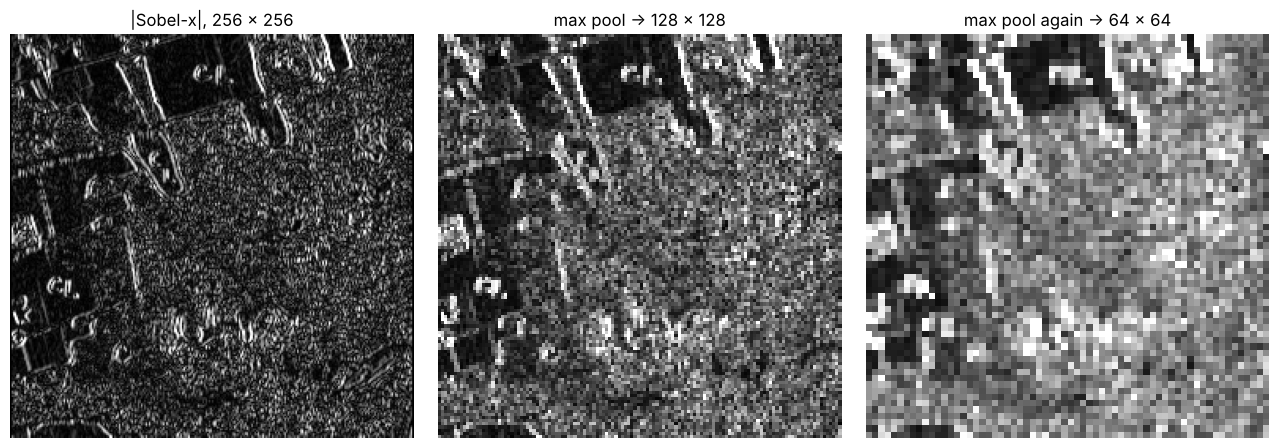

In [ ]:
edges = np.abs(cv2.filter2D(crop, -1, SOBEL_X))
p1 = F.max_pool2d(torch.tensor(edges)[None, None], 2)[0, 0].numpy()
p2 = F.max_pool2d(torch.tensor(p1)[None, None], 2)[0, 0].numpy()
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
for a, im, title in zip(ax, (edges, p1, p2), ("|Sobel-x|, 256 × 256", "max pool → 128 × 128", "max pool again → 64 × 64")):
    a.imshow(im, cmap="gray", vmin=0, vmax=np.percentile(edges, 99.5)); a.set_title(title, fontsize=12); a.axis("off")
plt.tight_layout(); plt.show()

## 10 · A small CNN for digits

conv (8 filters) → ReLU → pool → conv (16 filters) → ReLU → pool → one fully connected layer.

| layer | output (H × W × channels) | parameters |
|---|---|---|
| input | 8 × 8 × 1 | |
| conv 3×3, 8 filters, pad 1 | 8 × 8 × 8 | 8 × (3·3·1 + 1) = 80 |
| max pool 2 | 4 × 4 × 8 | 0 |
| conv 3×3, 16 filters, pad 1 | 4 × 4 × 16 | 16 × (3·3·8 + 1) = 1,168 |
| max pool 2 | 2 × 2 × 16 = 64 values | 0 |
| fully connected 64 → 10 | 10 | 64 × 10 + 10 = 650 |

PyTorch prints shapes as (channels, H, W), so 8 × 8 × 8 appears as (8, 8, 8) and
4 × 4 × 16 as (16, 4, 4).
(ReLUs after each conv; they have no parameters.)

In [ ]:
cnn = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(64, 10))
x0 = as_tensor(Xtr[:1])
for layer in cnn:
    x0 = layer(x0); print(f"{layer.__class__.__name__:10s} -> {tuple(x0.shape[1:])}")
print("parameters:", n_params(cnn))
t0 = time.time(); h_cnn = train(cnn)
print(f"trained in {time.time()-t0:.1f} s | train {h_cnn[-1,0]:.1%}  test {h_cnn[-1,1]:.1%}")

Conv2d     -> (8, 8, 8)
ReLU       -> (8, 8, 8)
MaxPool2d  -> (8, 4, 4)
Conv2d     -> (16, 4, 4)
ReLU       -> (16, 4, 4)
MaxPool2d  -> (16, 2, 2)
Flatten    -> (64,)
Linear     -> (10,)
parameters: 1898


trained in 5.4 s | train 100.0%  test 98.0%


Same test accuracy, fewer weights. The difference shows when the digits **move**. Shift
every test image by one pixel (the networks never saw shifted digits):

In [ ]:
def shift(a, dx, dy):
    out = np.zeros_like(a); H, W = a.shape[1:]
    out[:, max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)] = \
        a[:, max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)]
    return out

shifts = {"none": (0, 0), "right": (1, 0), "left": (-1, 0), "down": (0, 1), "up": (0, -1)}
res = {name: [accuracy(m, shift(Xte, *d), yte) for d in shifts.values()] for name, m in (("network", mlp), ("CNN", cnn))}
print("1-pixel shift:      " + "  ".join(f"{k:>6s}" for k in shifts))
for name, r in res.items():
    print(f"{name:8s} ({n_params(mlp if name == 'network' else cnn):,} w)  " + "  ".join(f"{v:6.1%}" for v in r))

1-pixel shift:        none   right    left    down      up
network  (2,410 w)   98.0%   43.7%   47.6%   45.0%   43.5%
CNN      (1,898 w)   98.0%   66.9%   74.3%   55.2%   61.3%


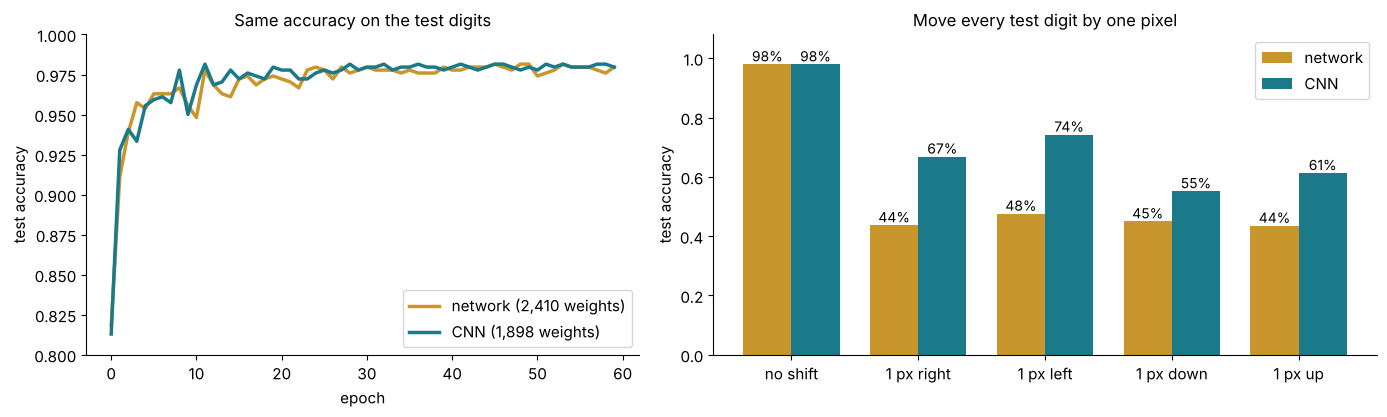

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1, 1.2]})
ax[0].plot(h_mlp[:, 1], color=GOLD, lw=2.5, label="network (2,410 weights)")
ax[0].plot(h_cnn[:, 1], color=TEAL, lw=2.5, label="CNN (1,898 weights)")
ax[0].set_ylim(0.8, 1.0); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("test accuracy")
ax[0].legend(loc="lower right"); ax[0].set_title("Same accuracy on the test digits", fontsize=12)
xs = np.arange(len(shifts)); w = 0.38
ax[1].bar(xs - w/2, res["network"], w, color=GOLD, label="network")
ax[1].bar(xs + w/2, res["CNN"], w, color=TEAL, label="CNN")
for i in range(len(shifts)):
    ax[1].text(i - w/2, res["network"][i] + 0.01, f"{res['network'][i]:.0%}", ha="center", fontsize=10)
    ax[1].text(i + w/2, res["CNN"][i] + 0.01, f"{res['CNN'][i]:.0%}", ha="center", fontsize=10)
ax[1].set_xticks(xs, ["no shift", "1 px right", "1 px left", "1 px down", "1 px up"])
ax[1].set_ylim(0, 1.08); ax[1].set_ylabel("test accuracy"); ax[1].legend(loc="upper right")
ax[1].set_title("Move every test digit by one pixel", fontsize=12)
plt.tight_layout(); plt.show()

Neither network is shift-proof — on an 8 × 8 image one pixel is 12% of the width — but the
CNN holds up much better: its filters are the same everywhere and pooling ignores small
moves. (Averaged over 5 random seeds, next cell: network 43–47% in every direction, CNN 55–77%
depending on the direction.)
L14 adds the other fix: **show the network shifted examples** while training (augmentation).

In [ ]:
# Same comparison over 5 seeds (about 40 s); the numbers quoted above
rows = []
for name, m in (("network", mlp), ("CNN", cnn)):
    r = []
    for s in range(5):
        train(m, seed=s)
        r.append([accuracy(m, shift(Xte, *d), yte) for d in shifts.values()])
    r = np.array(r); rows.append(r)
    print(f"{name:8s} mean " + "  ".join(f"{v:6.1%}" for v in r.mean(0)) + "   (min over shifted "
          f"{r[:, 1:].min():.0%}, max {r[:, 1:].max():.0%})")
train(cnn, seed=0); train(mlp, seed=0);     # back to the seed-0 models for §11

network  mean  97.5%   47.2%   45.6%   44.7%   43.4%   (min over shifted 40%, max 49%)


CNN      mean  98.1%   69.6%   76.7%   54.8%   59.5%   (min over shifted 42%, max 79%)


## 11 · What did the CNN learn?

The first layer's 8 filters (3 × 3) and what each one does to a test digit. Some look like
L3 edge kernels (positive on one side, negative on the other); others are harder to read.
An 8 × 8 digit leaves little room: in L13 we look at the first-layer filters of a large
network trained on photos, which look strikingly like the L3/L4 kernels.

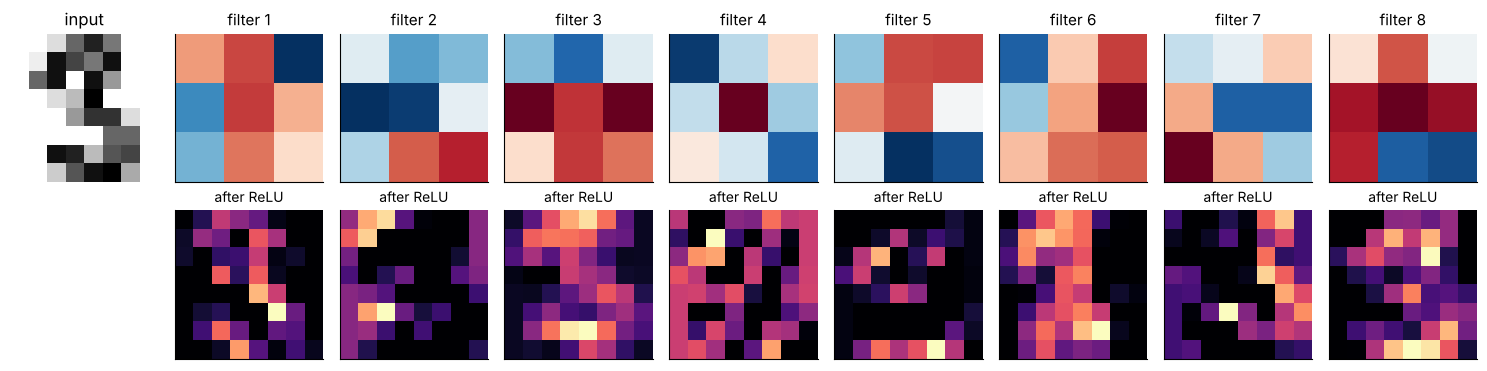

In [ ]:
k1 = cnn[0].weight.detach().numpy()[:, 0]                        # (8, 3, 3)
img = Xte[np.where(yte == 3)[0][0]]
with torch.no_grad():
    maps = torch.relu(cnn[0](as_tensor(img[None])))[0].numpy()  # (8, 8, 8)
fig, ax = plt.subplots(2, 9, figsize=(15, 3.8))
ax[0, 0].imshow(img, cmap="gray_r"); ax[0, 0].set_title("input", fontsize=12)
ax[1, 0].axis("off")
plt.subplots_adjust(hspace=0.35)
for i in range(8):
    v = np.abs(k1[i]).max()
    ax[0, i+1].imshow(k1[i], cmap="RdBu_r", vmin=-v, vmax=v); ax[0, i+1].set_title(f"filter {i+1}", fontsize=11)
    ax[1, i+1].imshow(maps[i], cmap="magma"); ax[1, i+1].set_title("after ReLU", fontsize=10)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
ax[0, 0].axis("off")
plt.tight_layout(); plt.show()

CNN errors: 11 of 540


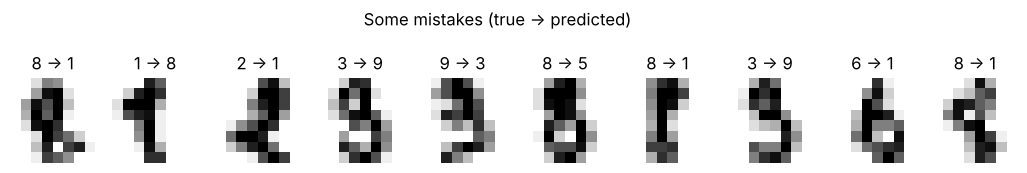

In [ ]:
with torch.no_grad():
    pred = cnn(as_tensor(Xte)).argmax(1).numpy()
wrong = np.where(pred != yte)[0]
print(f"CNN errors: {len(wrong)} of {len(yte)}")
fig, ax = plt.subplots(1, min(10, len(wrong)), figsize=(13, 1.9))
for a, i in zip(np.atleast_1d(ax), wrong[:10]):
    a.imshow(Xte[i], cmap="gray_r"); a.set_title(f"{yte[i]} → {pred[i]}", fontsize=12); a.axis("off")
plt.suptitle("Some mistakes (true → predicted)", fontsize=12, y=1.08)
plt.show()

## 12 · Try at home

**A. Another mystery kernel.** Replace `SOBEL_X` in §1 with the emboss kernel from L3,
`[[-2,-1,0],[-1,1,1],[0,1,2]]`. Does the network recover it? What happens with lr = 2?

**B. Learning rate.** In §7, train the network with `lr=0.0001` and `lr=1.0`. What do the
curves look like? Relate them to §5.

**C. Shuffled pixels.** Apply the same random permutation of the 64 pixels to every image
(train and test) and retrain both models. One of them does not care at all. Which, and why?

```python
perm = np.random.default_rng(0).permutation(64)
Xtr_s = Xtr.reshape(-1, 64)[:, perm].reshape(-1, 8, 8)   # same for Xte
```

**D. Count by hand, then check.** A conv layer with 32 filters of size 5 × 5 on an RGB image:
how many parameters? Check with `n_params(nn.Conv2d(3, 32, 5))`.

Next: **L13** (Wednesday) — real CNN architectures (AlexNet, VGG, ResNet). **AL7** (Friday) —
train your own CNN on CIFAR-10.